> **DEMO COPY: all numbers and charts below come from randomly generated sample data, not real customers.** Use `churn_analysis_clean.ipynb` with your own Excel file for real results.

# Customer Churn Analysis

**Question:** Which customers are leaving, what do they have in common, and how much monthly revenue is at stake?

**Data:** `customer_churn_data_raw.xlsx` with three sheets: `db_customer`, `db_subscription`, `db_support`.

**Plan:** clean the three tables, join them to one row per subscription, calculate churn KPIs, break churn down by plan, contract, state and age, then summarise what to act on.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

EXCEL_FILE = "customer_churn_data_raw.xlsx"

## 1. Load data

In [2]:
sheets = pd.read_excel(EXCEL_FILE, sheet_name=None)   # dict of {sheet name: DataFrame}
df_customer     = sheets["db_customer"].copy()
df_subscription = sheets["db_subscription"].copy()
df_support      = sheets["db_support"].copy()

for name, d in sheets.items():
    print(f"{name:16s} rows={len(d):5d}  cols={list(d.columns)}")

db_customer      rows=  600  cols=['customerid', 'name', 'dob', 'gender', 'state', 'country', 'interests', 'pincode']
db_subscription  rows=  600  cols=['customerid', 'plan_type', 'contract_type', 'monthly_charges', 'subscription_start_date', 'renewal_date', 'cancellation_date', 'churn_score']
db_support       rows=  900  cols=['customerid', 'complaint_date', 'escalations', 'col_1', 'comment']


## 2. Clean

### Customer table

In [3]:
df_customer = df_customer.rename(columns={"name": "customer_name"})
df_customer = df_customer.drop(columns=["interests", "pincode"], errors="ignore")
df_customer["dob"] = pd.to_datetime(df_customer["dob"])
df_customer["gender"] = df_customer["gender"].replace({"Men": "Male", "Women": "Female"})

# Fill missing country from other rows with the same state
state_to_country = (df_customer.dropna(subset=["country"])
                    .drop_duplicates("state").set_index("state")["country"])
df_customer["country"] = df_customer["country"].fillna(df_customer["state"].map(state_to_country))

print("Missing country after fill:", df_customer["country"].isna().sum())
print("Genders:", df_customer["gender"].unique())
print("Duplicate customer ids:", df_customer["customerid"].duplicated().sum())

Missing country after fill: 0
Genders: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Duplicate customer ids: 0


### Subscription table

In [4]:
date_cols = ["subscription_start_date", "renewal_date", "cancellation_date"]
df_subscription[date_cols] = df_subscription[date_cols].apply(pd.to_datetime)

# A customer has churned if they have a cancellation date
df_subscription["churn_flag"] = df_subscription["cancellation_date"].notna().astype(int)
df_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               600 non-null    int64         
 1   plan_type                600 non-null    str           
 2   contract_type            600 non-null    str           
 3   monthly_charges          600 non-null    int64         
 4   subscription_start_date  600 non-null    datetime64[us]
 5   renewal_date             600 non-null    datetime64[us]
 6   cancellation_date        184 non-null    datetime64[us]
 7   churn_score              600 non-null    int64         
 8   churn_flag               600 non-null    int64         
dtypes: datetime64[us](3), int64(4), str(2)
memory usage: 42.3 KB


### Support table

In [5]:
df_support = df_support.drop(columns=["col_1", "comment"], errors="ignore")
df_support["complaint_date"] = pd.to_datetime(df_support["complaint_date"])

print("Complaint rows:", len(df_support), "| unique customers:", df_support["customerid"].nunique())

Complaint rows: 900 | unique customers: 363


## 3. Join the tables

A customer can have several complaints. Joining them directly would duplicate subscription rows and inflate every KPI, so complaints are rolled up to **one row per customer** first.

In [6]:
support_per_customer = (df_support
    .assign(is_escalated=lambda d: (d["escalations"] == "Y").astype(int))
    .groupby("customerid")
    .agg(complaint_count=("customerid", "size"),
         escalated=("is_escalated", "max"),          # 1 if any complaint was escalated
         last_complaint_date=("complaint_date", "max"))
    .reset_index())

df = (df_subscription
      .merge(df_customer, on="customerid", how="left", validate="m:1")
      .merge(support_per_customer, on="customerid", how="left", validate="m:1"))

# Customers with no support record have zero complaints
df["complaint_count"] = df["complaint_count"].fillna(0).astype(int)
df["escalated"] = df["escalated"].fillna(0).astype(int)

assert len(df) == len(df_subscription), "join changed the row count"
print("Rows before join:", len(df_subscription), "| after:", len(df))

Rows before join: 600 | after: 600


## 4. Customer age and tenure

In [7]:
# Use the latest date in the data as 'today' so results don't change when the notebook is re-run
as_of = max(df["subscription_start_date"].max(),
            df["cancellation_date"].max(),
            df["renewal_date"].max())
print("As-of date:", as_of.date())

df["customer_age"] = ((as_of - df["dob"]).dt.days / 365.25).astype(int)
df["age_group"] = pd.cut(df["customer_age"], bins=[0, 24, 34, 44, 54, 120],
                         labels=["<25", "25-34", "35-44", "45-54", "55+"])

end_date = df["cancellation_date"].fillna(as_of)
df["tenure_days"] = (end_date - df["subscription_start_date"]).dt.days

df["churn_risk"] = pd.cut(df["churn_score"], bins=[-np.inf, 50, 70, np.inf],
                          labels=["low", "med", "high"], right=False)
df[["customerid", "customer_age", "age_group", "tenure_days", "churn_risk"]].head()

As-of date: 2025-11-30


,customerid,customer_age,age_group,tenure_days,churn_risk
0,1,31,25-34,708,low
1,2,55,55+,639,low
2,3,48,45-54,677,med
3,4,44,35-44,449,high
4,5,47,45-54,869,med


## 5. Headline KPIs

In [8]:
churn_rate     = df["churn_flag"].mean() * 100
arpu           = df["monthly_charges"].mean()
revenue_at_risk = df.loc[df["churn_flag"] == 1, "monthly_charges"].sum()
total_revenue   = df["monthly_charges"].sum()

kpis = pd.Series({
    "Customers / subscriptions":        len(df),
    "Churn rate (%)":                   churn_rate,
    "Retention rate (%)":               100 - churn_rate,
    "ARPU (monthly)":                   arpu,
    "Avg tenure (days)":                df["tenure_days"].mean(),
    "Monthly revenue lost to churn":    revenue_at_risk,
    "  as % of total monthly revenue":  revenue_at_risk / total_revenue * 100,
    "Escalation rate (%)":              df["escalated"].mean() * 100,
    "Avg complaints per customer":      df["complaint_count"].mean(),
    "Correlation: escalation vs churn": df["escalated"].corr(df["churn_flag"]),
})
kpis.to_frame("value")

,value
Customers / subscriptions,600.00
Churn rate (%),30.67
Retention rate (%),69.33
ARPU (monthly),878.02
Avg tenure (days),544.01
Monthly revenue lost to churn,"162,358.00"
as % of total monthly revenue,30.82
Escalation rate (%),44.17
Avg complaints per customer,1.50
Correlation: escalation vs churn,0.03


## 6. Where is churn highest?

In [9]:
def churn_summary(by):
    out = (df.groupby(by, observed=True)
             .agg(customers=("customerid", "nunique"),
                  churn_rate_pct=("churn_flag", lambda s: s.mean() * 100),
                  monthly_revenue=("monthly_charges", "sum"),
                  revenue_lost=("monthly_charges", lambda s: s[df.loc[s.index, "churn_flag"] == 1].sum()))
             .sort_values("churn_rate_pct", ascending=False))
    return out

by_plan, by_contract, by_state, by_age = (churn_summary(c) for c in
                                          ["plan_type", "contract_type", "state", "age_group"])
by_plan

,customers,churn_rate_pct,monthly_revenue,revenue_lost
plan_type,,,,
Basic,204,31.37,169446,55195
Premium,218,30.73,192609,58607
Standard,178,29.78,164759,48556


In [10]:
by_contract

,customers,churn_rate_pct,monthly_revenue,revenue_lost
contract_type,,,,
Monthly,302,31.46,263506,81497
Annual,298,29.87,263308,80861


In [11]:
by_state

,customers,churn_rate_pct,monthly_revenue,revenue_lost
state,,,,
Karnataka,153,32.03,133466,42753
Bavaria,164,31.71,143947,46735
Texas,139,29.50,121611,33916
Kerala,144,29.17,127790,38954


In [12]:
by_age

,customers,churn_rate_pct,monthly_revenue,revenue_lost
age_group,,,,
35-44,148,34.46,123012,42856
45-54,176,30.11,154351,48120
55+,164,29.27,149196,41343
25-34,112,28.57,100255,30039


### Plan and contract together

In [13]:
pd.pivot_table(df, index="plan_type", columns="contract_type",
               values="churn_flag", aggfunc="mean").mul(100).round(1)

contract_type,Annual,Monthly
plan_type,,
Basic,27.60,35.40
Premium,29.40,32.10
Standard,33.30,26.60


### Does the churn score actually predict churn?

In [14]:
(df.groupby("churn_risk", observed=True)["churn_flag"]
   .agg(customers="size", actual_churn_pct=lambda s: s.mean() * 100))

,customers,actual_churn_pct
churn_risk,,
low,283,28.27
med,131,32.06
high,186,33.33


## 7. Charts

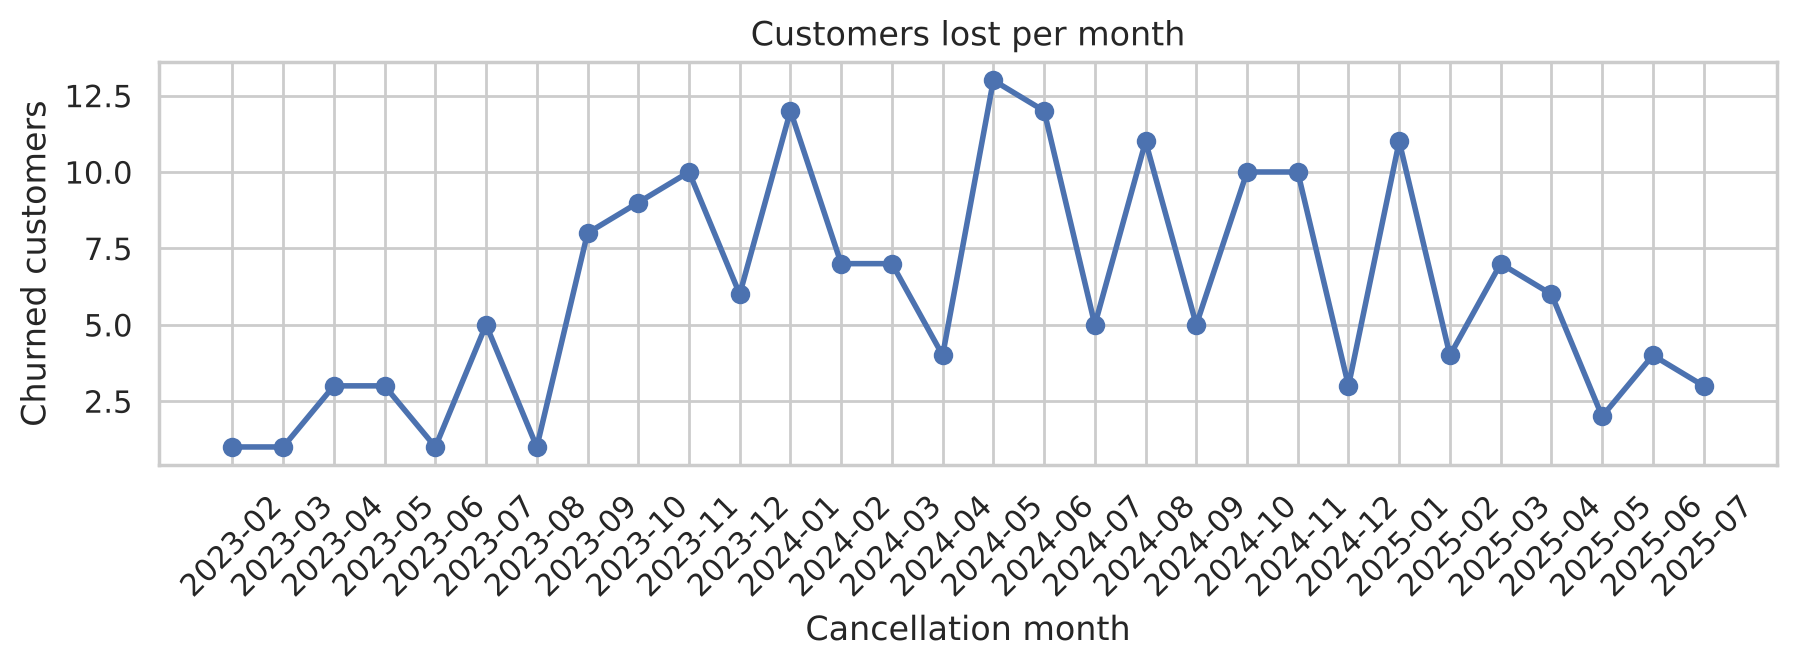

In [15]:
monthly = (df[df["churn_flag"] == 1]
           .groupby(df["cancellation_date"].dt.to_period("M")).size())

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(monthly.index.astype(str), monthly.values, marker="o", linewidth=2)
ax.set(title="Customers lost per month", xlabel="Cancellation month", ylabel="Churned customers")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

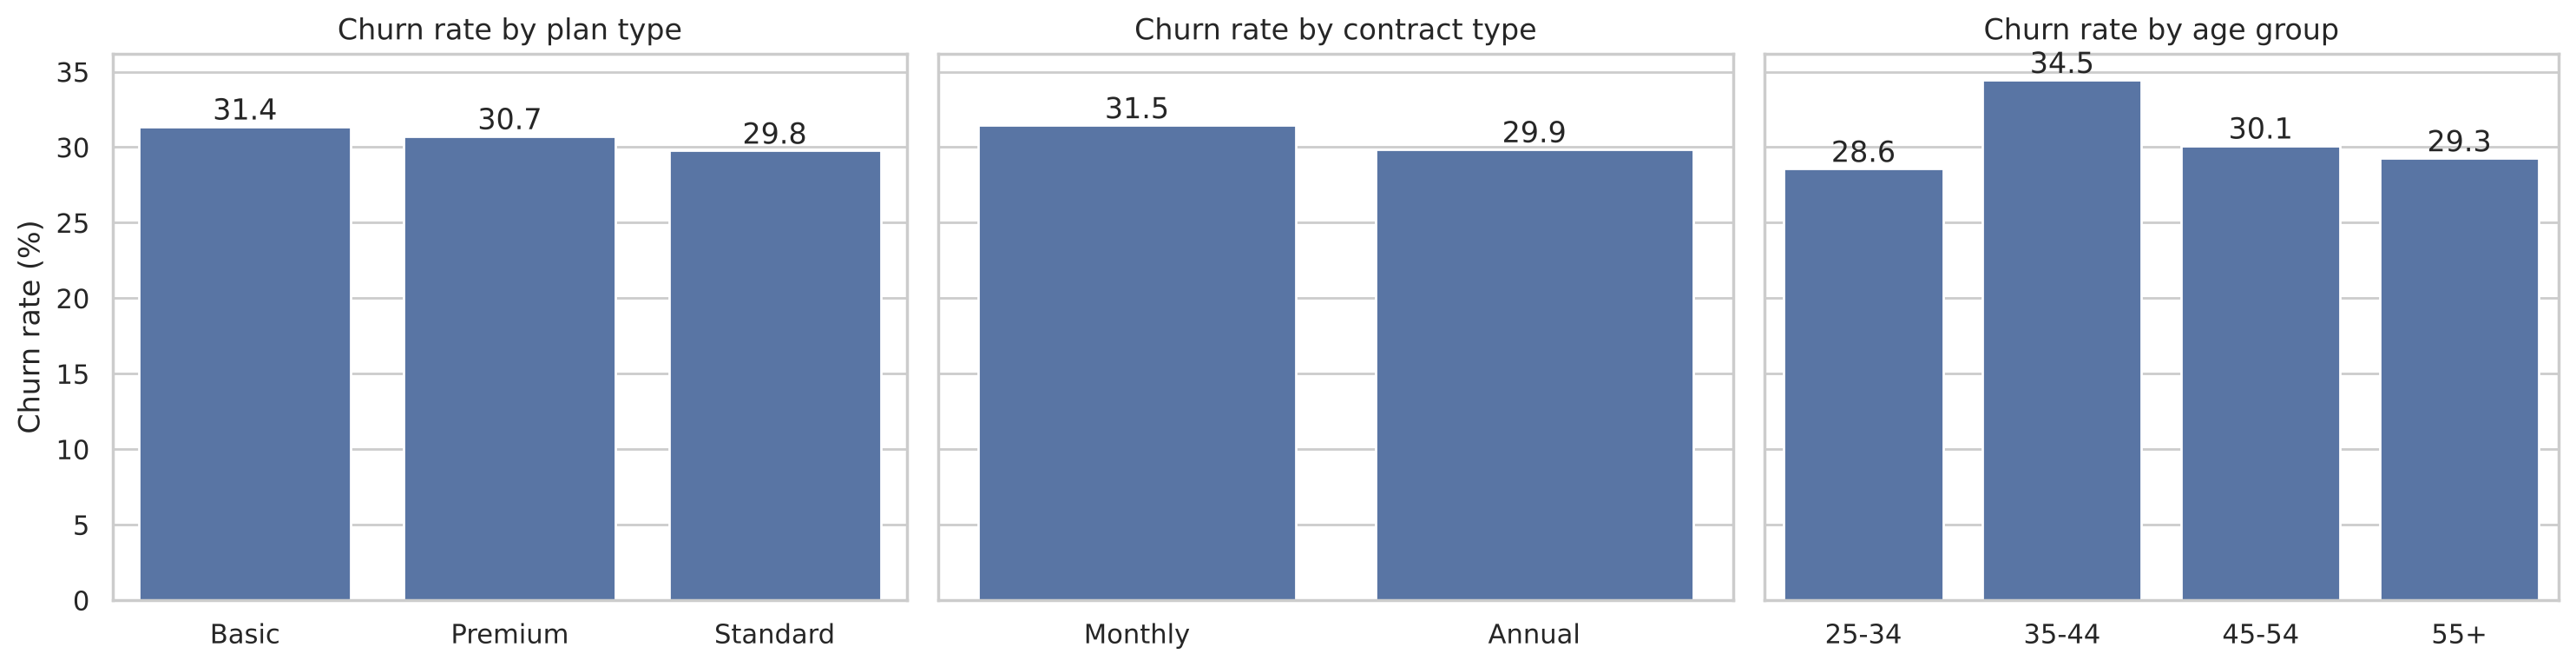

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (tbl, title) in zip(axes, [(by_plan, "Plan type"), (by_contract, "Contract type"), (by_age.sort_index(), "Age group")]):
    sns.barplot(x=tbl.index.astype(str), y=tbl["churn_rate_pct"], ax=ax)
    ax.set(title=f"Churn rate by {title.lower()}", xlabel="", ylabel="Churn rate (%)")
    for c in ax.containers: ax.bar_label(c, fmt="%.1f")
plt.tight_layout(); plt.show()

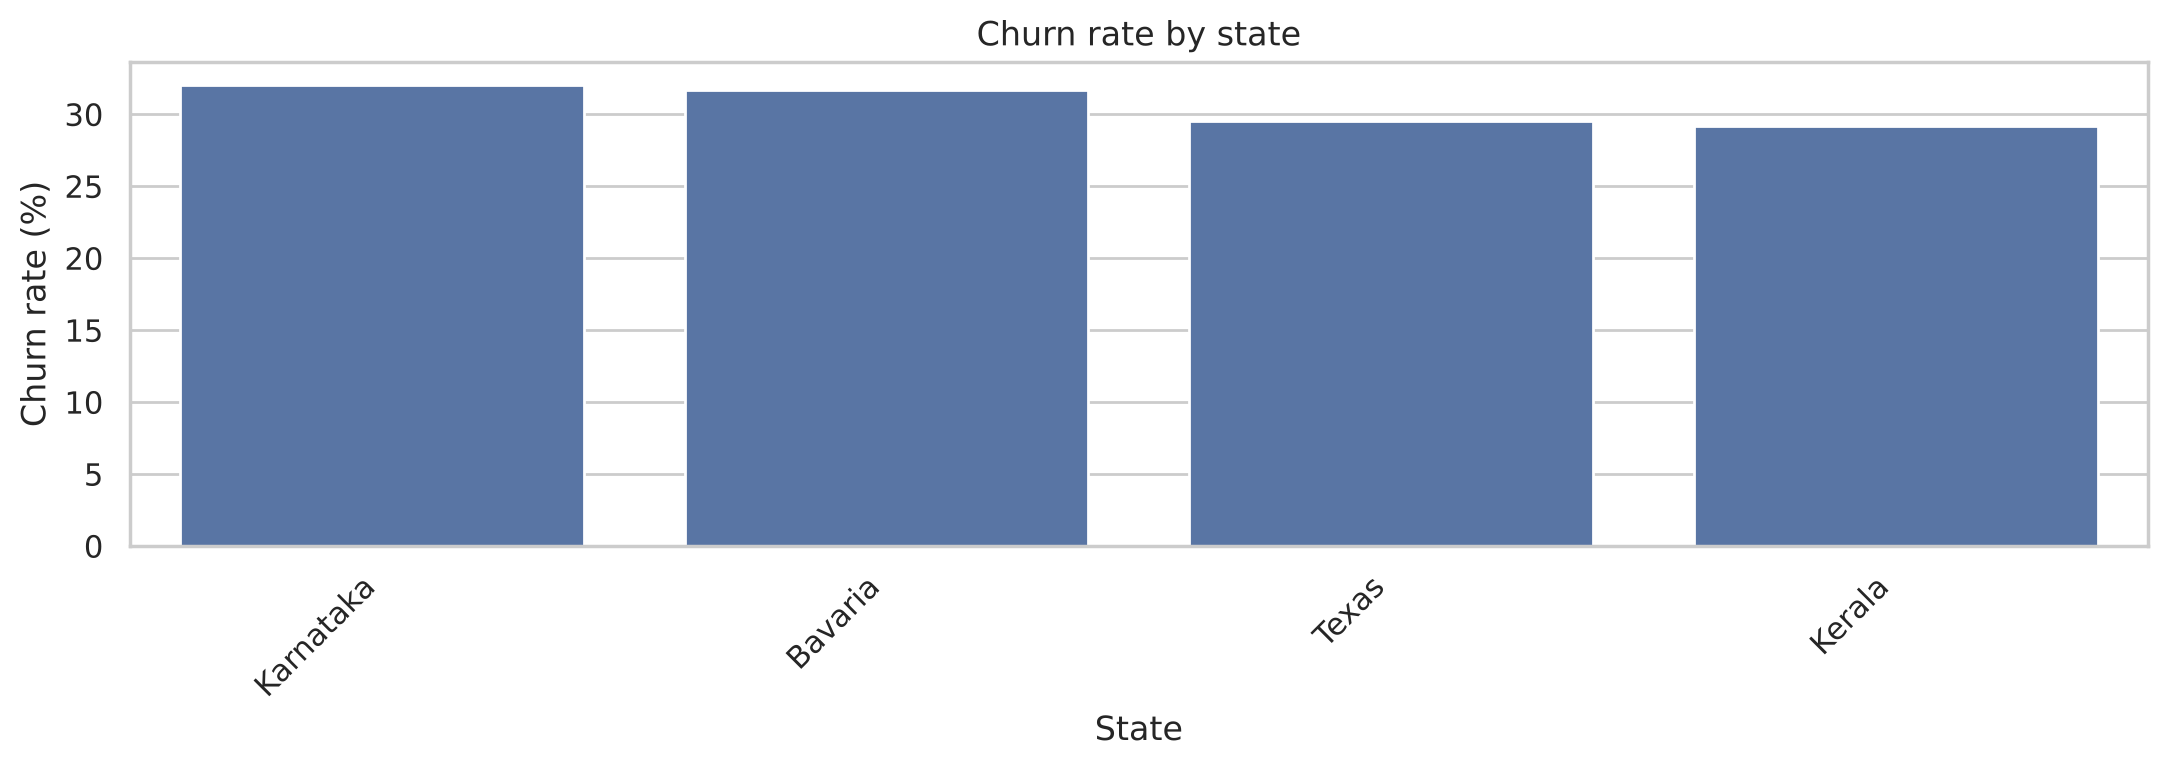

In [17]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(x=by_state.index, y=by_state["churn_rate_pct"], ax=ax)
ax.set(title="Churn rate by state", xlabel="State", ylabel="Churn rate (%)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

### Correlation heatmap

Categories are encoded in their natural order (Basic < Standard < Premium, Monthly < Annual, low < med < high). Alphabetical codes would give meaningless correlations.

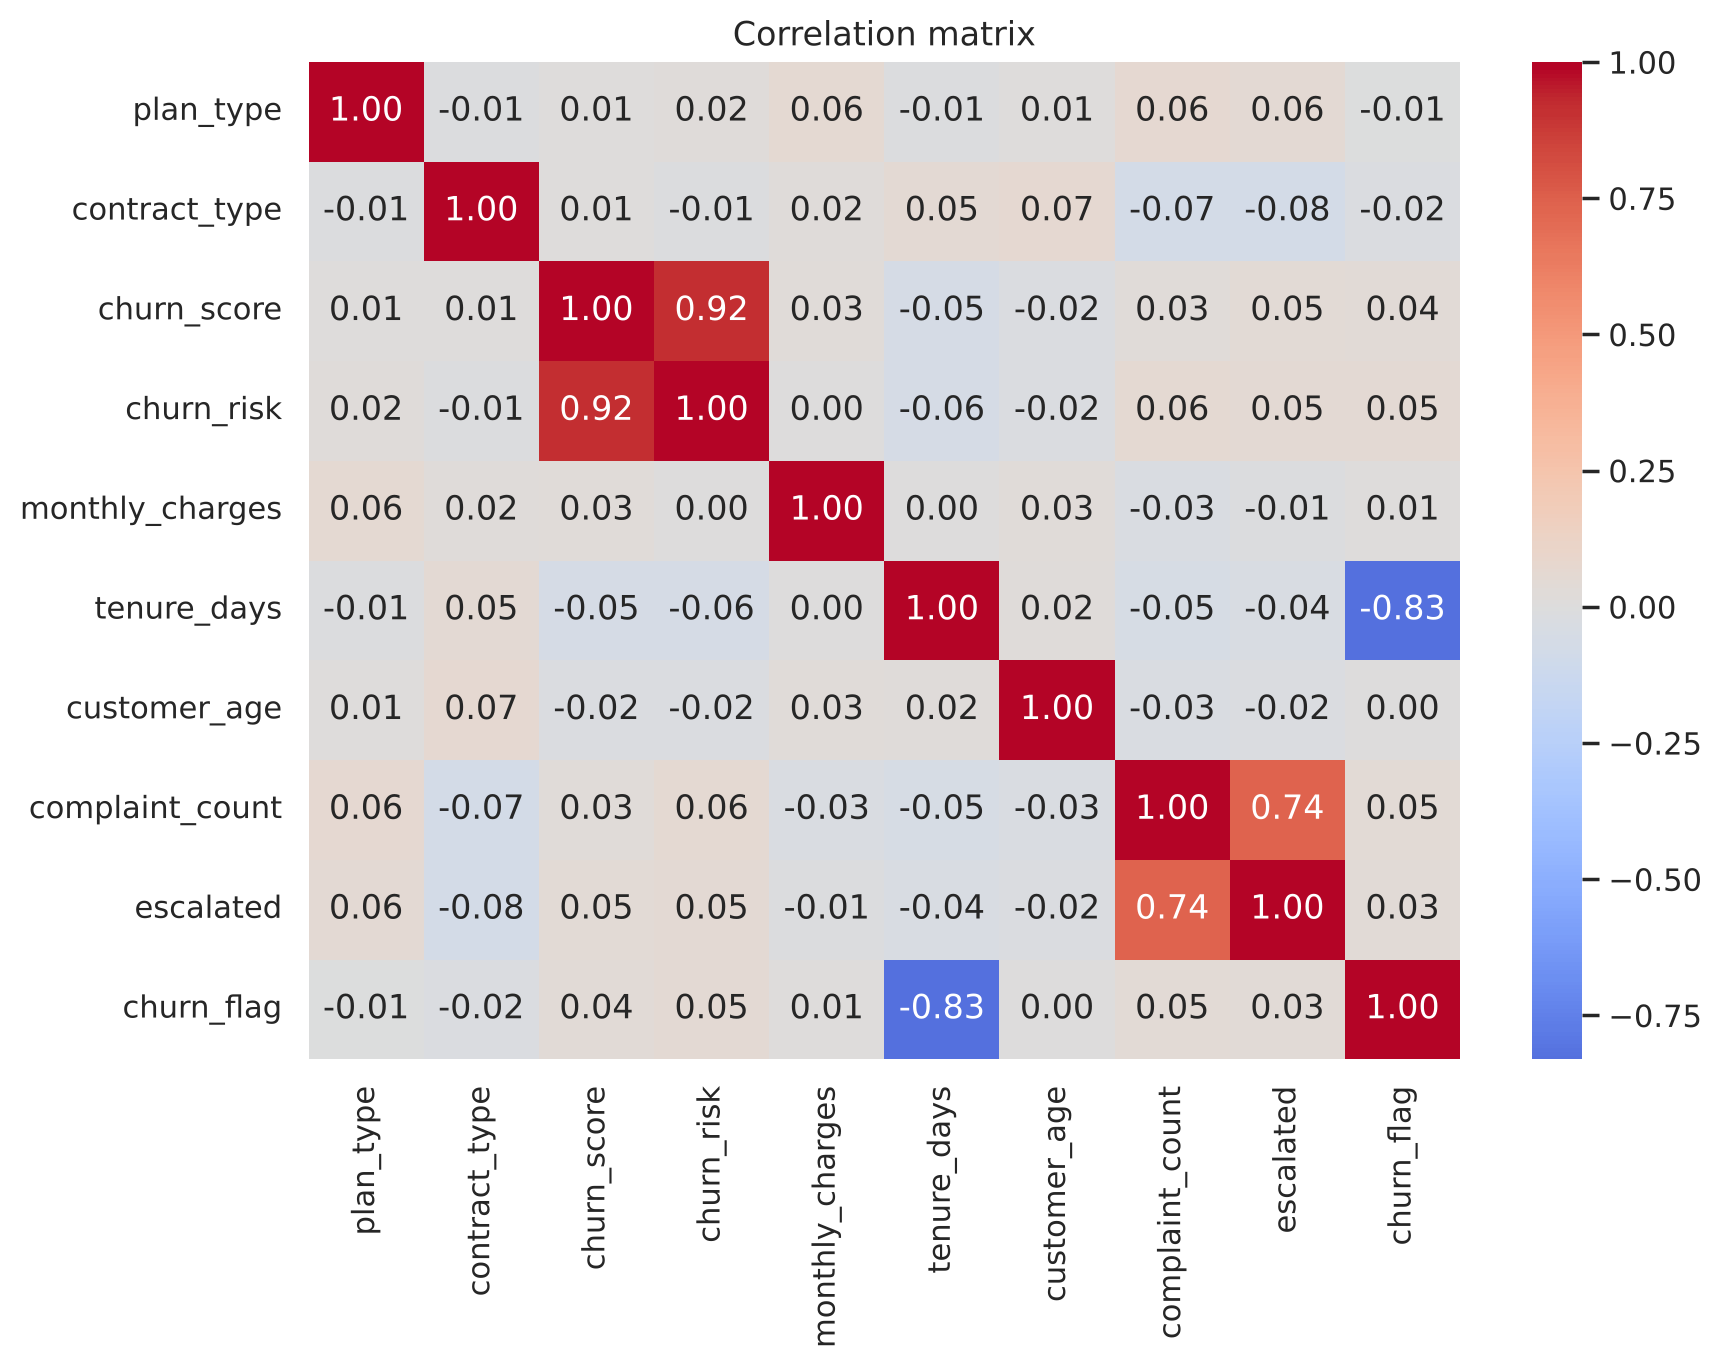

In [18]:
orders = {"plan_type": ["Basic", "Standard", "Premium"],
          "contract_type": ["Monthly", "Annual"],
          "churn_risk": ["low", "med", "high"]}

enc = df[["plan_type", "contract_type", "churn_score", "churn_risk",
          "monthly_charges", "tenure_days", "customer_age",
          "complaint_count", "escalated", "churn_flag"]].copy()
for col, order in orders.items():
    enc[col] = pd.Categorical(enc[col], categories=order, ordered=True).codes

plt.figure(figsize=(9, 7))
sns.heatmap(enc.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

## 8. Findings (computed from the data above)

In [19]:
def top(tbl, label):
    r = tbl.iloc[0]
    return f"- Highest churn {label}: **{tbl.index[0]}** at {r['churn_rate_pct']:.1f}% ({int(r['customers'])} customers)"

from IPython.display import Markdown
Markdown("\n".join([
    f"- Overall churn is **{churn_rate:.1f}%**, costing **{revenue_at_risk:,.0f}** in monthly revenue "
    f"({revenue_at_risk/total_revenue*100:.1f}% of the total).",
    top(by_plan, "plan"), top(by_contract, "contract"), top(by_state, "state"), top(by_age, "age group"),
    f"- Escalated complainers churn at {df[df.escalated==1].churn_flag.mean()*100:.1f}% vs "
    f"{df[df.escalated==0].churn_flag.mean()*100:.1f}% for everyone else.",
]))

- Overall churn is **30.7%**, costing **162,358** in monthly revenue (30.8% of the total).
- Highest churn plan: **Basic** at 31.4% (204 customers)
- Highest churn contract: **Monthly** at 31.5% (302 customers)
- Highest churn state: **Karnataka** at 32.0% (153 customers)
- Highest churn age group: **35-44** at 34.5% (148 customers)
- Escalated complainers churn at 32.5% vs 29.3% for everyone else.

## 9. Recommendations

*Write these in your own words after running the notebook:*

1. **Who to target first:** (the segment from the tables above with the highest churn and revenue lost)
2. **What to change:** (for example a contract offer, faster handling of escalations, a plan review)
3. **How to measure it:** (which KPI should move, and by how much)

**Limitations:** snapshot data, no cause for cancellation, and `churn_score` is used as given without knowing how it was built.